In [1]:
import numpy as np
import matplotlib.pyplot as plt
from session_data import *
from visualize import *
from antenna_array import *

%load_ext autoreload
%autoreload 2

Session: session_130954
Start: 2025-11-16 13:09:54.406331
End: 2025-11-16 13:22:26.440133
Duration: 752.0 seconds
Total Samples: 161
Data Points: 161
Images: 161



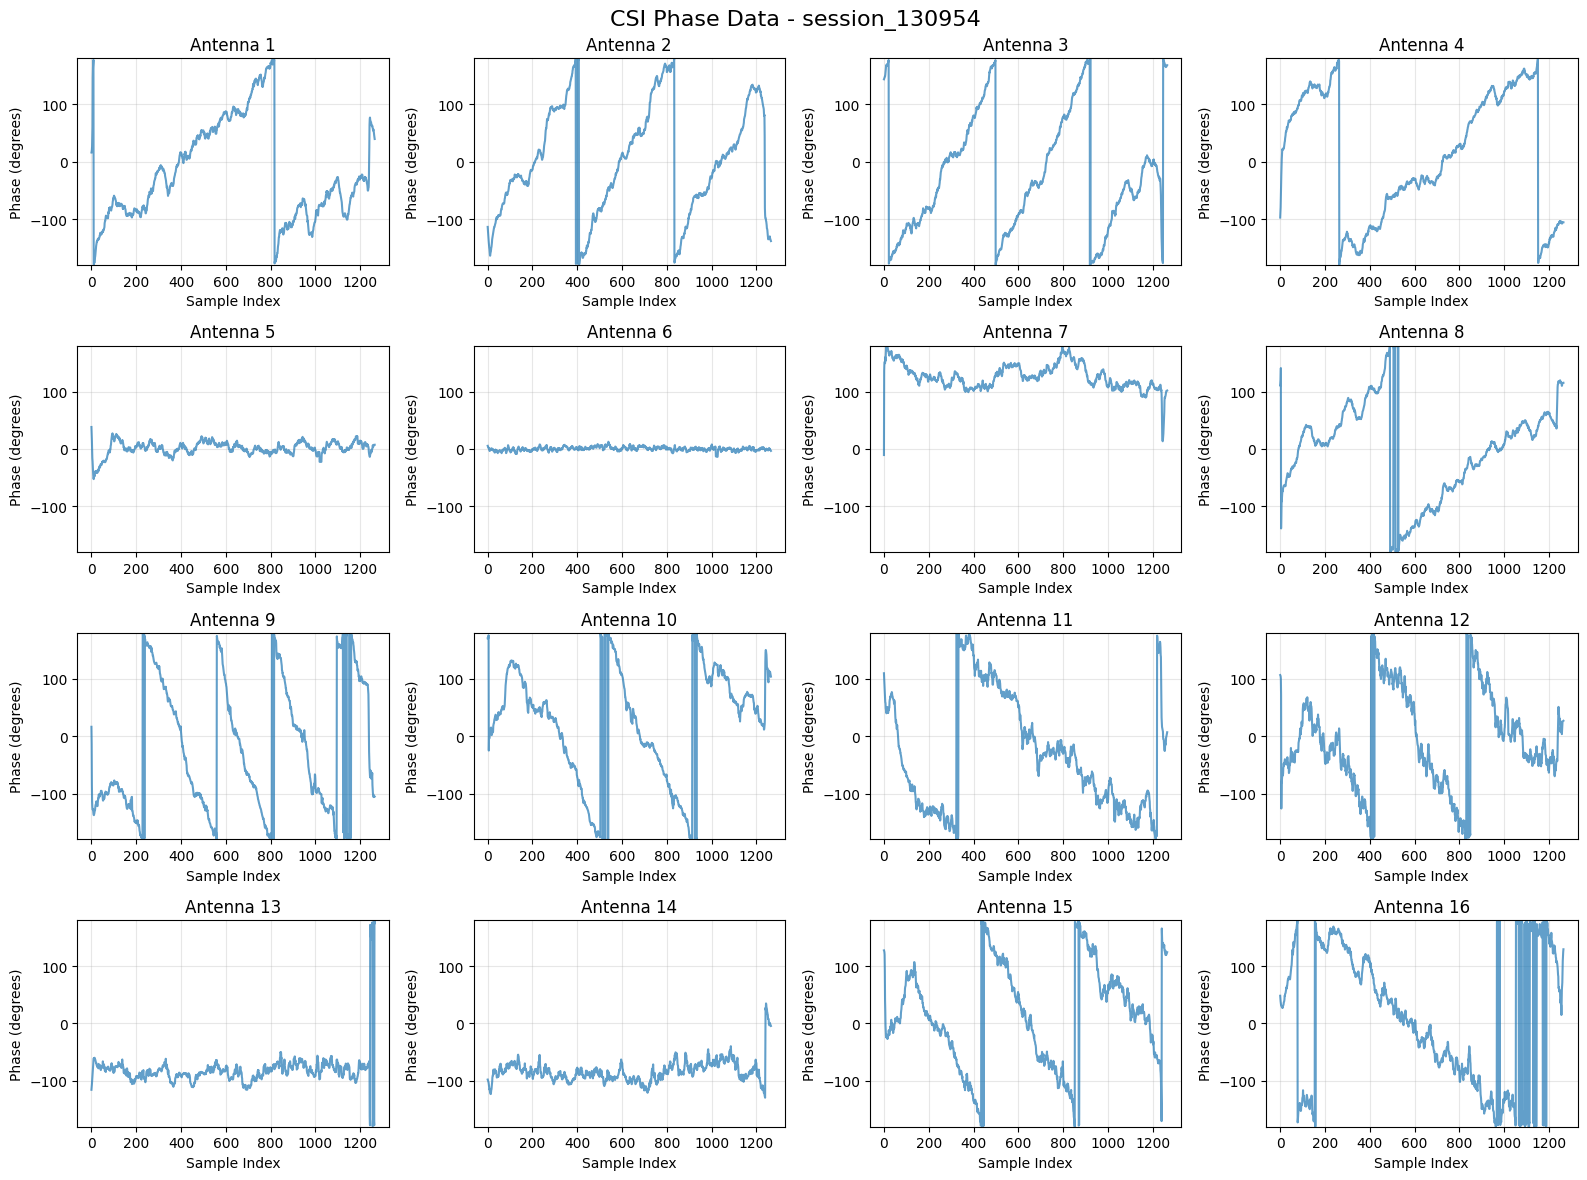

In [51]:
session_dir = Path("../data/2025-11-16/rotation_80_direct")
session = SessionData.from_directory(session_dir)
session.load_all_router_batches()
print(session.summary())

plot_csi_phase_data(session)

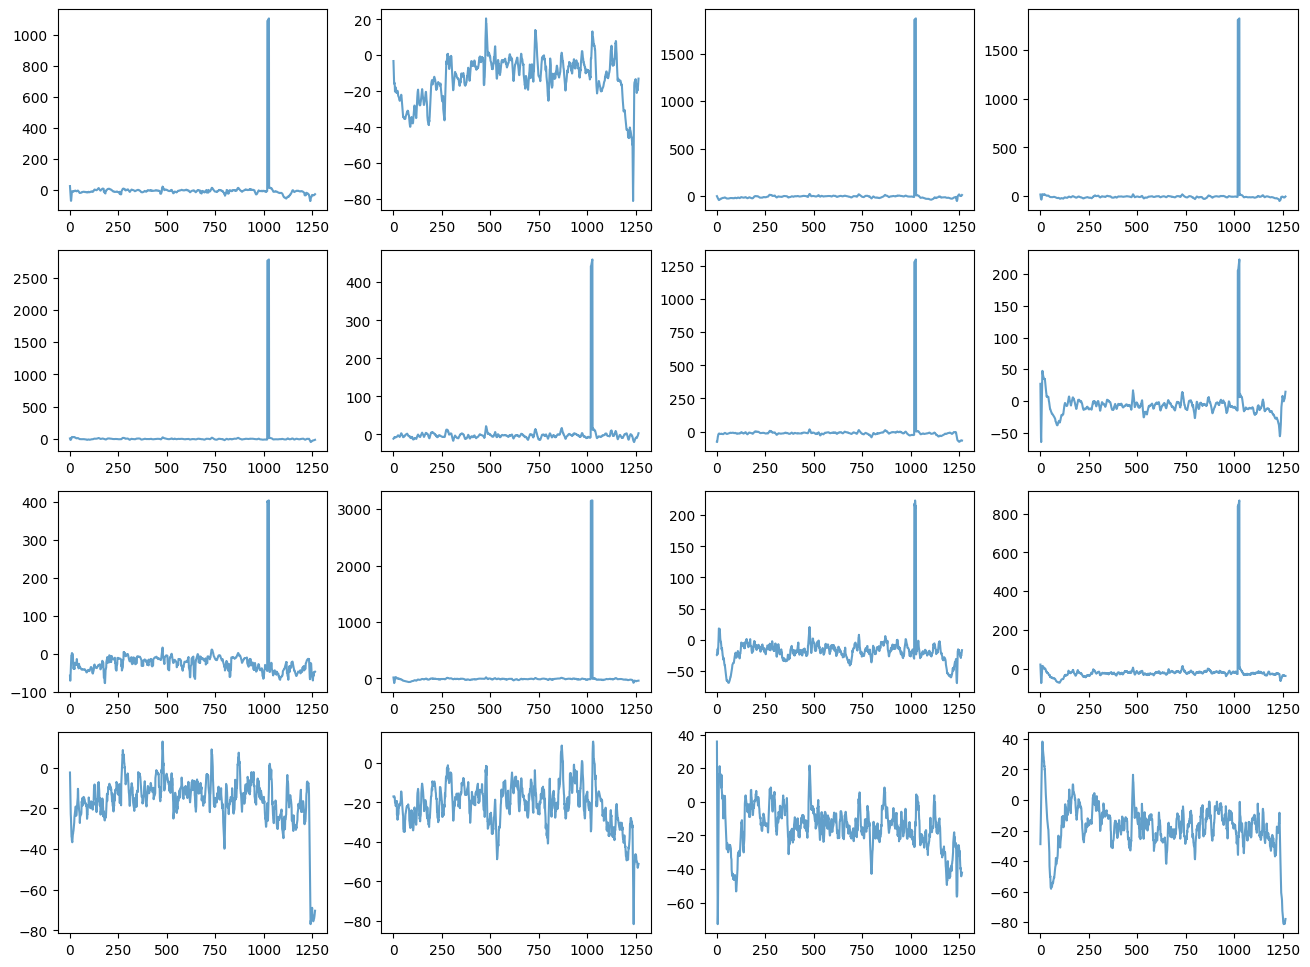

In [52]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()
channel_data, _ = read_and_process_csi_data(session)
magnitude_data = np.abs(channel_data)

# Set titles and labels for each subplot
for antenna in range(16):
    axes[antenna].plot(magnitude_data[:, antenna] - magnitude_data[:, 5].mean(), markersize=3, alpha=0.7)

In [58]:
channel_data.shape

(1592, 16)

In [59]:
channel_data = np.zeros((1, 16), dtype=np.complex128)

for dp in session.data_points:
    # Check if router batch is loaded
    if dp.router_batch is None:
        continue
        
    csi_data = dp.router_batch.csi_processed_data
    
    # Check if CSI data is not empty and has the right shape
    if csi_data.size == 0 or len(csi_data.shape) < 2:
        continue
    
    channel_data = np.vstack((channel_data, csi_data))

num_samples = channel_data.shape[0] - 1
valid_antennas = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13, 21, 23, 25, 27]

theta_vals = np.linspace(-80, 80, 150)
theta_vals = np.deg2rad(theta_vals)
num_samples = 150

# Create antenna arrays for each sample
spacing = 0.58 * 58.32 / 60.48
antenna_arrays = [AntennaArray() for _ in range(num_samples)]
antenna_arrays_real = [AntennaArray() for _ in range(num_samples)]
for i in range(num_samples):
    averaged_channel_data = np.mean(channel_data[i*10:(i+1)*10, :], axis=0)

    for antenna in range(32):
        if antenna not in valid_antennas:
            continue
        antenna_arrays[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
            0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)
        antenna_arrays_real[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
            0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)

    w = antenna_arrays[i].get_conjugate_beamformer(az=theta_vals[i], el=0)
    antenna_arrays[i].set_weights(w)
    antenna_arrays_real[i].set_weights(np.conjugate(averaged_channel_data))

In [60]:
# Least-Squares Style Estimation
element_factor = np.zeros((np.shape(theta_vals)[0], 16))

for i, theta in enumerate(theta_vals):
    sum1 = np.sum([antenna_arrays[i].get_array_response(theta, 0) for i in range(num_samples)], axis=0)
    sum2 = np.sum([antenna_arrays[i].get_array_response(theta, 0)**2 for i in range(num_samples)], axis=0)
    numerator = np.sum([antenna_arrays[i].get_array_response(theta, 0) * channel_data[i] for i in range(num_samples)], axis=0)
    denominator = sum2
    
    denominator[denominator < 1e-10] = 1e-10
    element_factor[i, :] = numerator / denominator

/tmp/ipykernel_1121808/3999411056.py:11: ComplexWarning: Casting complex values to real discards the imaginary part
  element_factor[i, :] = numerator / denominator


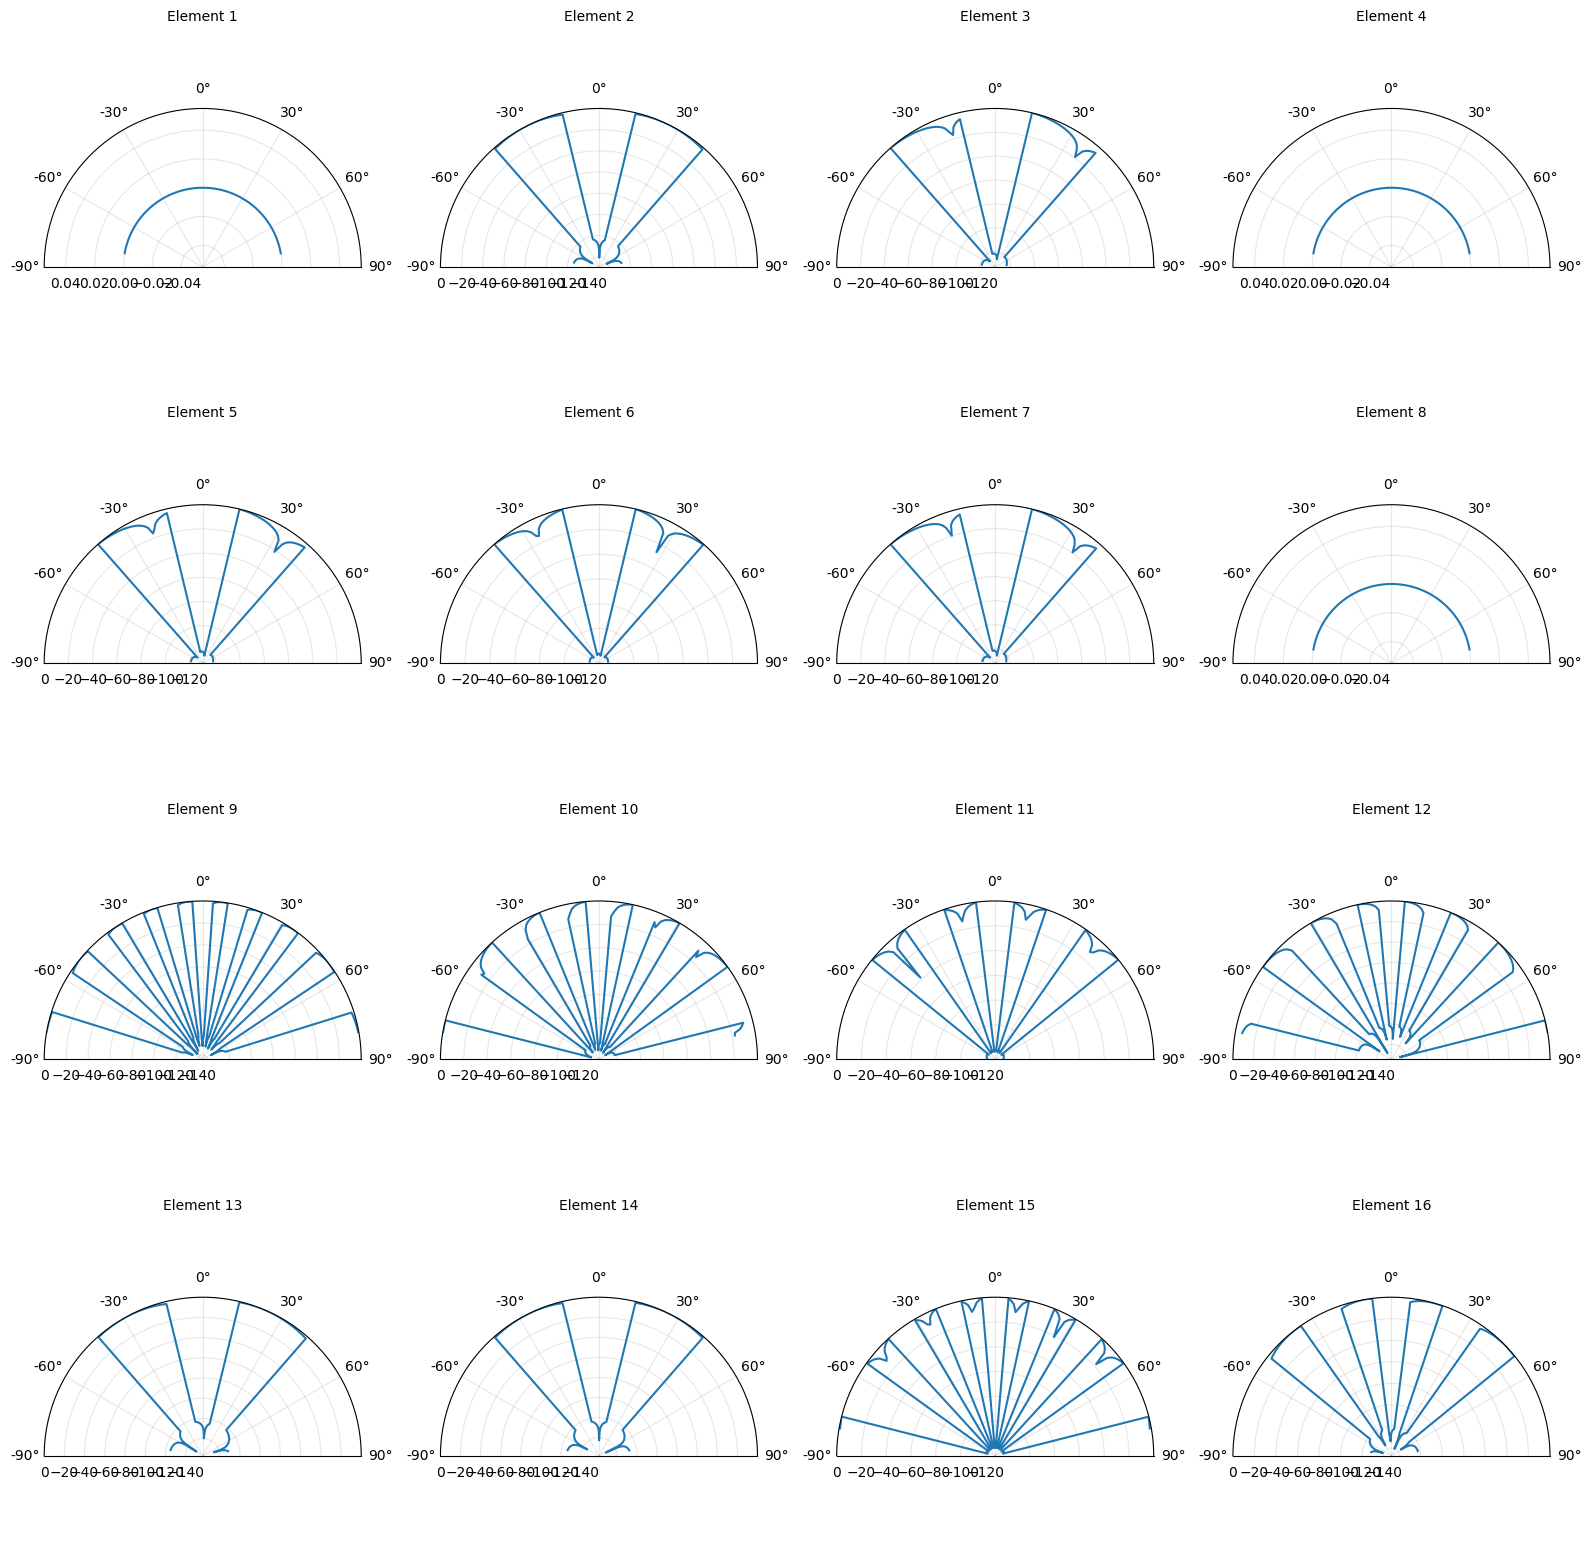

In [62]:
# Create figure with 16 subplots (4x4 grid)
fig = plt.figure(figsize=(16, 16))

# Plot first 16 elements
for idx in range(16):
    ax = plt.subplot(4, 4, idx + 1, projection='polar')
    
    # Get element pattern for this antenna
    element_pattern = np.abs(element_factor[:, idx])
    element_pattern_db = 10 * np.log10(element_pattern)
    
    # Normalize to peak
    element_pattern_db = element_pattern_db - np.max(element_pattern_db)
    
    # Plot
    ax.plot(theta_vals, element_pattern_db, linewidth=1.5)
    
    # Configure polar plot
    ax.set_theta_zero_location('N')  # 0° at top
    ax.set_theta_direction(-1)  # Clockwise
    ax.set_thetamin(-90)  # Set range from -90
    ax.set_thetamax(90)   # to 90 degrees
    # ax.set_ylim([-100, 3])  # dB range
    ax.set_title(f'Element {idx+1}', fontsize=10)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('element_patterns_16_1.png', dpi=150, bbox_inches='tight')
plt.show()